# 06 · Test final et interprétation

**Étape 10** (slides 22, 30) puis **étape 11** (slide 52) du cas pratique.

Toutes les décisions ont été prises sur le train seul, par validation croisée : modèle, hyperparamètres, calibration, seuil. On réentraîne la procédure complète sur tout `X_train`, puis on ouvre le test, **une seule fois**.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, brier_score_loss, confusion_matrix, log_loss, roc_auc_score

from financial_inclusion_africa import config, models, viz
from financial_inclusion_africa.data import load_split
from financial_inclusion_africa.evaluate import (bootstrap_ci, bootstrap_metrics, classification_metrics,
                                                 cost_at_threshold, ece_noise_floor, evaluate_cv,
                                                 expected_calibration_error, expected_counts, fold_scores,
                                                 format_summary, full_classification_report)

viz.set_style()
pd.set_option("display.precision", 4)
RS = config.RANDOM_STATE
X_train, X_test, y_train, y_test = load_split()

## Étape 10 · Évaluer une seule fois sur le test

### Les décisions, figées avant d'ouvrir le test

| Décision | Choix | Étape |
|---|---|---|
| Variables | variables du guide + nos variables (`features="all"`) | 3 |
| Encodage | catégories natives, modalités rares (< 20) regroupées | 3, 6 |
| Modèle | LightGBM | 6 |
| Hyperparamètres | meilleur essai Optuna (`models.LGBM_PARAMS`) | 7 |
| Calibration | aucune : probabilités brutes, déjà calibrées | 8 |
| Seuil | $t^* = C_{FP} / (C_{FP} + C_{FN}) = 1/11$ | 9 |

Le guide calibre le modèle final par `CalibratedClassifierCV(..., method="isotonic")` ; l'étape 8 a montré que ce n'est pas utile ici (ECE dans le plancher de bruit, PR-AUC et log-loss un peu moins bonnes). On applique donc la procédure **telle qu'elle a été validée**, sans couche de calibration.

In [2]:
print(f"Modèle final : {models.FINAL_MODEL}")
print(f"Seuil        : {models.FINAL_THRESHOLD:.4f}")
pd.Series(models.LGBM_PARAMS, name="hyperparamètres").to_frame()

Modèle final : LightGBM réglé
Seuil        : 0.0909


,hyperparamètres
learning_rate,0.0488
num_leaves,6.0000
min_child_samples,23.0000
subsample,0.5609
subsample_freq,1.0000
colsample_bytree,0.5307
reg_lambda,1.9346
n_estimators,341.0000


**Estimation de validation croisée** de cette procédure (mêmes plis que partout : c'est la valeur à comparer au test, Q10.2).

In [3]:
cv_row, cv_res = evaluate_cv(models.make_final(), X_train, y_train, name=models.FINAL_MODEL)
cv_folds = fold_scores(cv_res)
format_summary(pd.DataFrame([cv_row])).T

,LightGBM réglé
pr_auc,0.581 ± 0.024
roc_auc,0.861 ± 0.010
brier,0.085 ± 0.003
logloss,0.283 ± 0.009
acc,0.888 ± 0.005
precision_t,0.301 ± 0.005
recall_t,0.852 ± 0.020
cost_t,0.244 ± 0.012
temps (s),0.61


### Réentraîner sur tout le train

Le modèle final voit les 18 819 lignes du train, 25 % de plus que dans chaque pli de validation croisée. Conséquence pour les modalités rares (Q2.6) : *Other/Dont know/RTA* (`education_level`) a 21 occurrences dans le train ; dans chaque pli (15 à 18) elle était regroupée dans `infrequent`, ici elle dépasse le seuil de 20 et devient une **modalité à part**. *Dont know* (`marital_status`, 8 lignes) reste regroupée.

In [4]:
final = models.make_final().fit(X_train, y_train)
native = final.named_steps["nativecategories"]
pd.Series({col: ", ".join(cats) for col, cats in native.categories_.items()}, name="modalités apprises").to_frame()

,modalités apprises
country,"Kenya, Rwanda, Tanzania, Uganda, infrequent"
location_type,"Rural, Urban, infrequent"
cellphone_access,"No, Yes, infrequent"
gender_of_respondent,"Female, Male, infrequent"
relationship_with_head,"Child, Head of Household, Other non-relatives,..."
marital_status,"Divorced/Seperated, Married/Living together, S..."
education_level,"No formal education, Other/Dont know/RTA, Prim..."
job_type,"Dont Know/Refuse to answer, Farming and Fishin..."
age_group,"16-25, 26-35, 36-50, 51-65, 66+, infrequent"


### Ouvrir le test

C'est la **première et la seule** fois que `X_test` et `y_test` sont utilisés pour mesurer un modèle. Aucune décision ne sera modifiée après cette cellule (Q10.3).

In [5]:
p_test = final.predict_proba(X_test)[:, 1]
y_pred = (p_test >= models.FINAL_THRESHOLD).astype(int)
print(f"{len(y_test)} personnes, dont {int(y_test.sum())} ont un compte bancaire ({y_test.mean():.2%})")

4705 personnes, dont 662 ont un compte bancaire (14.07%)


### Q10.1 · Tableau final sur le test

Intervalles de confiance à 95 % par **bootstrap** (slide 30) : 1 000 rééchantillons avec remise des 4 705 personnes du test, centiles 2,5 et 97,5. Toutes les métriques sont calculées sur les **mêmes** rééchantillons.

In [6]:
T = models.FINAL_THRESHOLD
METRICS = {
    "PR-AUC": average_precision_score,
    "ROC-AUC": roc_auc_score,
    "Brier": brier_score_loss,
    "log-loss": lambda y, p: log_loss(y, p, labels=[0, 1]),
    "ECE": expected_calibration_error,
    "précision au seuil": lambda y, p: ((p >= T) & (y == 1)).sum() / max((p >= T).sum(), 1),
    "recall au seuil": lambda y, p: ((p >= T) & (y == 1)).sum() / y.sum(),
    "coût / personne (USD)": lambda y, p: cost_at_threshold(y, p, T) / len(y),
}
test_table = bootstrap_metrics(y_test, p_test, METRICS, n_boot=1000, seed=RS)

# Le code du guide (bootstrap_ci) donne le même intervalle pour la PR-AUC
lo, hi = bootstrap_ci(y_test, p_test, average_precision_score, n_boot=1000, seed=RS)
print(f"bootstrap_ci, PR-AUC : [{lo:.4f} ; {hi:.4f}]")
test_table.round(4)

bootstrap_ci, PR-AUC : [0.5590 ; 0.6349]


,test,IC 95 % bas,IC 95 % haut,écart-type bootstrap
PR-AUC,0.5969,0.5590,0.6349,0.0194
ROC-AUC,0.8755,0.8609,0.8885,0.0069
Brier,0.0826,0.0771,0.0880,0.0027
log-loss,0.2743,0.2591,0.2901,0.0078
ECE,0.0149,0.0106,0.0250,0.0037
précision au seuil,0.3059,0.2858,0.3262,0.0105
recall au seuil,0.8761,0.8514,0.9017,0.0133
coût / personne (USD),0.2270,0.2073,0.2468,0.0102


In [7]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
n_test = len(y_test)
decision = pd.DataFrame({
    "contactés": [tp + fp, n_test, 0],
    "FP (contact inutile)": [fp, int((y_test == 0).sum()), 0],
    "FN (personne oubliée)": [fn, 0, int(y_test.sum())],
    "coût (USD)": [config.COST_FP * fp + config.COST_FN * fn,
                   config.COST_FP * (y_test == 0).sum(), config.COST_FN * y_test.sum()],
}, index=[f"{models.FINAL_MODEL} au seuil t*", "contacter tout le monde", "ne contacter personne"])
decision["coût / personne"] = decision["coût (USD)"] / n_test
display(decision.round(3))
print(full_classification_report(y_test, p_test, T))

,contactés,FP (contact inutile),FN (personne oubliée),coût (USD),coût / personne
LightGBM réglé au seuil t*,1896,1316,82,1068.0,0.227
contacter tout le monde,4705,4043,0,2021.5,0.430
ne contacter personne,0,0,662,3310.0,0.704


              precision    recall  f1-score   support

      No (0)     0.9708    0.6745    0.7960      4043
     Yes (1)     0.3059    0.8761    0.4535       662

    accuracy                         0.7029      4705
   macro avg     0.6384    0.7753    0.6247      4705
weighted avg     0.8773    0.7029    0.7478      4705



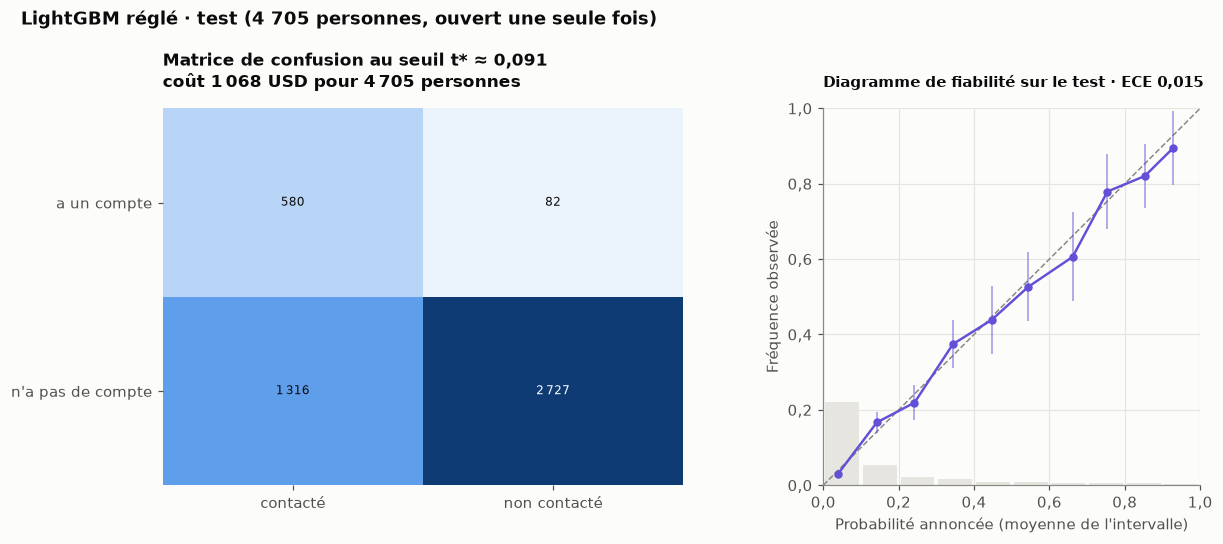

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.1]})
cm = pd.DataFrame([[tp, fn], [fp, tn]], index=["a un compte", "n'a pas de compte"],
                  columns=["contacté", "non contacté"])
viz.heatmap(axes[0], cm, f"Matrice de confusion au seuil t* ≈ 0,091\ncoût {viz.fmt_int(decision.iloc[0]['coût (USD)'])} USD "
            f"pour {viz.fmt_int(n_test)} personnes", fmt="{:,.0f}", vmin=0, vmax=n_test * 0.6)
axes[0].set_xticks(range(2), cm.columns, rotation=0, ha="center")
ece = test_table.loc["ECE", "test"]
viz.reliability(axes[1], y_test, p_test, hist=True, color=viz.COMPOSITION[1])
axes[1].set_title(f"Diagramme de fiabilité sur le test · ECE {viz.fr(f'{ece:.3f}')}", fontsize=10)
fig.suptitle(f"{models.FINAL_MODEL} · test (4 705 personnes, ouvert une seule fois)", x=0.02, ha="left",
             fontweight="bold")
fig.tight_layout()
viz.save(fig, "10_test_confusion_fiabilite")
plt.show()

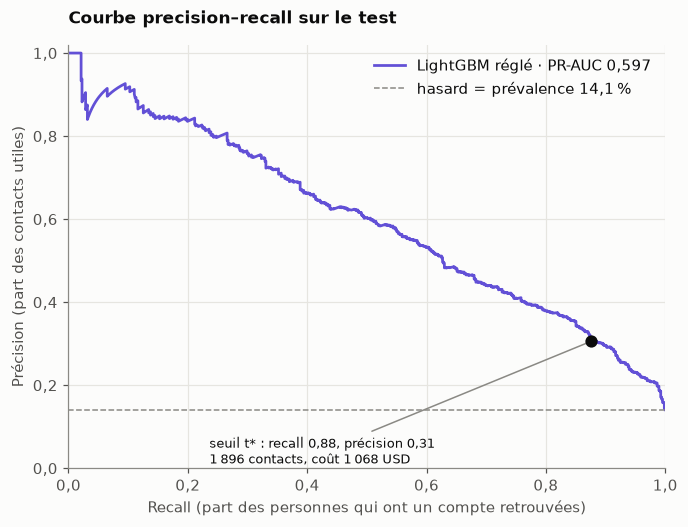

In [9]:
# Courbe precision–recall du modèle final sur le test, avec le point de fonctionnement au seuil t*
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, p_test)
ap = test_table.loc["PR-AUC", "test"]
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(recall, precision, color=viz.COMPOSITION[1], lw=1.8,
        label=f"{models.FINAL_MODEL} · PR-AUC {viz.fr(f'{ap:.3f}')}")
ax.axhline(y_test.mean(), color=viz.INK_3, ls="--", lw=1,
           label=f"hasard = prévalence {viz.fmt_pct(y_test.mean())}")
r_t, p_t = tp / (tp + fn), tp / (tp + fp)
ax.plot(r_t, p_t, "o", color=viz.INK, ms=7, zorder=4)
ax.annotate(f"seuil t* : recall {viz.fr(f'{r_t:.2f}')}, précision {viz.fr(f'{p_t:.2f}')}\n"
            f"{viz.fmt_int(tp + fp)} contacts, coût {viz.fmt_int(decision.iloc[0]['coût (USD)'])} USD",
            (r_t, p_t), xytext=(-250, -80), textcoords="offset points", fontsize=8.5,
            arrowprops={"arrowstyle": "-", "color": viz.INK_3})
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Recall (part des personnes qui ont un compte retrouvées)",
       ylabel="Précision (part des contacts utiles)", title="Courbe precision–recall sur le test")
viz.fr_axis(ax, "both", "{:.1f}")
ax.legend(loc="upper right")
viz.save(fig, "10_courbe_precision_recall")
plt.show()

**Réponse Q10.1.**

| Métrique (test) | Valeur | IC 95 % bootstrap | Validation croisée |
|---|---|---|---|
| **PR-AUC** | **0,597** | [0,559 ; 0,635] | 0,581 ± 0,024 |
| ROC-AUC | 0,876 | [0,861 ; 0,889] | 0,861 ± 0,010 |
| Brier | 0,083 | [0,077 ; 0,088] | 0,085 ± 0,003 |
| log-loss | 0,274 | [0,259 ; 0,290] | 0,283 ± 0,009 |
| ECE | 0,015 | [0,011 ; 0,025] | 0,005 (hors pli) |
| Précision / recall au seuil $t^*$ | 0,306 / 0,876 | [0,286 ; 0,326] / [0,851 ; 0,902] | 0,301 / 0,852 |
| **Coût par personne** | **0,227 USD** | [0,207 ; 0,247] | 0,244 ± 0,012 |

**Matrice de confusion au seuil $t^*$** : 1 896 personnes contactées sur 4 705 ; 580 vrais positifs, 1 316 contacts inutiles, **82 personnes oubliées** sur 662, 2 727 vrais négatifs. **Coût total : 1 068 USD** (1 316 × 0,5 + 82 × 5), contre 2 021,5 USD pour contacter tout le monde et 3 310 USD pour ne contacter personne.

**Calibration sur le test.** L'ECE (0,015) est un peu au-dessus de son plancher de bruit sur 4 705 personnes (moyenne 0,010, 95e centile 0,014, ci-dessous) : le modèle annonce 680 personnes qui ont un compte pour 662 réelles (+2,7 %, 0,9 écart-type du bruit attendu). Écart léger, sans conséquence pour le seuil (le coût est plat autour de $t^*$, étape 9).

In [10]:
floor = ece_noise_floor(p_test)
print(f"ECE test {expected_calibration_error(y_test, p_test):.4f} · plancher : moyenne {floor['moyenne']:.4f}, "
      f"95e centile {floor['95e centile']:.4f}")
expected_counts(y_test, p_test, X_test["country"]).round(3)

ECE test 0.0149 · plancher : moyenne 0.0098, 95e centile 0.0137


,réel,attendu,écart,erreur relative,écart-type attendu,écart / écart-type
Kenya,314.0,303.399,-10.601,-0.034,12.475,-0.850
Rwanda,195.0,213.492,18.492,0.095,11.922,1.551
Tanzania,117.0,121.206,4.206,0.036,8.504,0.495
Uganda,36.0,41.621,5.621,0.156,5.353,1.050
Total,662.0,679.718,17.718,0.027,19.968,0.887


### Q10.2 · L'estimation de validation croisée tombe-t-elle dans l'intervalle du test ?

In [11]:
COMPARE = {"PR-AUC": ("pr_auc", "PR-AUC"), "ROC-AUC": ("roc_auc", "ROC-AUC"), "Brier": ("brier", "Brier"),
           "Coût par personne (USD)": ("cost_t", "coût / personne (USD)")}
rows = {}
for label, (cv_key, test_key) in COMPARE.items():
    cv_mean = cv_row[(cv_key, "val", "mean")]
    lo, hi = test_table.loc[test_key, ["IC 95 % bas", "IC 95 % haut"]]
    rows[label] = {"CV (moyenne des plis)": cv_mean, "CV écart-type": cv_row[(cv_key, "val", "std")],
                   "test": test_table.loc[test_key, "test"], "IC 95 % bas": lo, "IC 95 % haut": hi,
                   "CV dans l'IC ?": "oui" if lo <= cv_mean <= hi else "non"}
q102 = pd.DataFrame(rows).T
q102

,CV (moyenne des plis),CV écart-type,test,IC 95 % bas,IC 95 % haut,CV dans l'IC ?
PR-AUC,0.5815,0.0237,0.5969,0.559,0.6349,oui
ROC-AUC,0.8612,0.0103,0.8755,0.8609,0.8885,oui
Brier,0.0845,0.0025,0.0826,0.0771,0.088,oui
Coût par personne (USD),0.2437,0.0123,0.227,0.2073,0.2468,oui


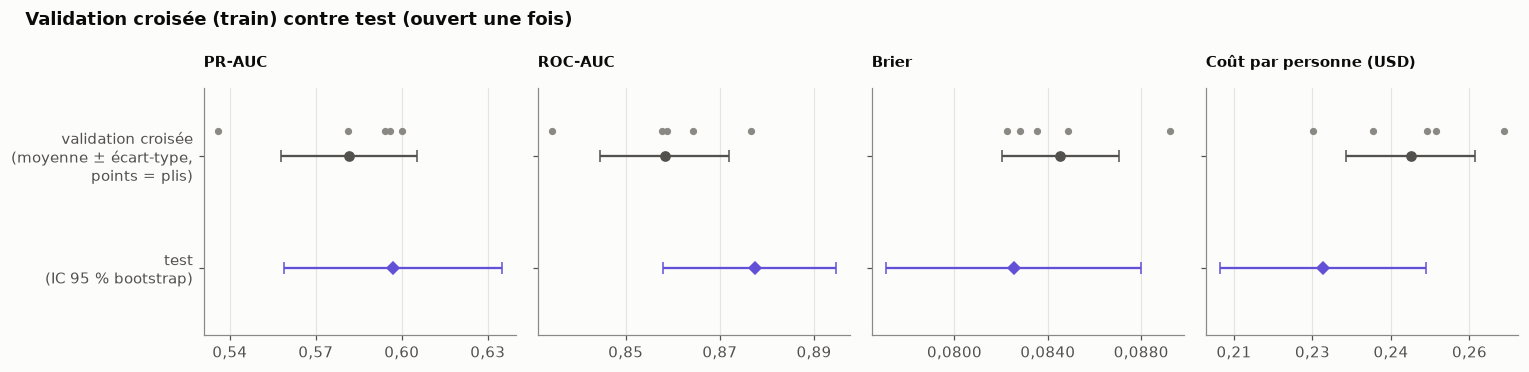

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (label, (cv_key, test_key)) in zip(axes, COMPARE.items()):
    folds = cv_folds[cv_key].to_numpy()
    mean, sd = folds.mean(), folds.std()
    ax.errorbar(mean, 1, xerr=sd, fmt="o", color=viz.INK_2, capsize=4, ms=6)
    ax.scatter(folds, np.full(len(folds), 1.22), color=viz.INK_3, s=14, zorder=3)
    t_val = test_table.loc[test_key, "test"]
    lo, hi = test_table.loc[test_key, ["IC 95 % bas", "IC 95 % haut"]]
    ax.errorbar(t_val, 0, xerr=[[t_val - lo], [hi - t_val]], fmt="D", color=viz.COMPOSITION[1], capsize=4, ms=6)
    ax.set_yticks([0, 1], ["test\n(IC 95 % bootstrap)", "validation croisée\n(moyenne ± écart-type,\npoints = plis)"])
    ax.set_ylim(-0.6, 1.6)
    ax.set_title(label, fontsize=10)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    viz.fr_axis(ax, "x", {"brier": "{:.4f}", "cost_t": "{:.2f}"}.get(cv_key, "{:.2f}"))
    ax.grid(axis="y", visible=False)
    if ax is not axes[0]:
        ax.set_yticklabels([])
fig.suptitle("Validation croisée (train) contre test (ouvert une fois)", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
viz.save(fig, "10_cv_contre_test")
plt.show()

**Réponse Q10.2. Oui, pour les quatre métriques** : PR-AUC 0,581, ROC-AUC 0,861, Brier 0,085 et coût 0,244 USD par personne tombent dans les intervalles du test. Le test est même un peu **meilleur** que la validation croisée (PR-AUC 0,597, coût 0,227 USD par personne).

**La ROC-AUC est à la limite** : 0,8612 pour une borne basse de 0,8609. Avec une autre graine de bootstrap (0 au lieu de 42), la borne devient 0,8621 et la validation croisée tombe juste dehors : la frontière d'un intervalle à 95 % n'est pas une ligne nette. Ce n'est pas alarmant :

- l'intervalle bootstrap ne mesure que le hasard de **l'échantillon de test**, pour un modèle fixé ; il ignore la variabilité du découpage et de l'entraînement, que l'écart-type entre plis (0,010) capture. L'écart (0,014) vaut 1,4 écart-type entre plis ;
- le modèle final est entraîné sur **25 % de lignes en plus** que dans chaque pli : il peut être un peu meilleur que l'estimation de validation croisée, légèrement pessimiste (slide 22) ;
- l'écart va dans le sens **favorable**. Une fuite d'information se verrait plutôt dans une validation croisée trop belle, démentie par le test ; c'est l'inverse ici.

**Conclusion** : la validation croisée était une estimation fiable de la performance sur des personnes nouvelles ; le protocole (test sous scellé, mêmes plis, décisions prises sur le train) a tenu. On rapporte les chiffres du **test** comme estimation finale, avec leurs intervalles : PR-AUC 0,597 [0,559 ; 0,635], coût 0,227 USD par personne [0,207 ; 0,247]. La largeur de ces intervalles (± 0,04 de PR-AUC) rappelle que les écarts de 0,003 entre candidats aux étapes 7–9 étaient indiscernables sur un test de cette taille.

### Retour sur Q2.6 · la modalité rare *Other/Dont know/RTA*

Le modèle final lui a donné sa propre modalité (21 occurrences dans le train). Change-t-elle les prédictions des 14 personnes du test qui la portent ? On compare avec les mêmes personnes, modalité remplacée par une valeur jamais vue (donc `infrequent`).

In [13]:
rare = X_test["education_level"] == "Other/Dont know/RTA"
p_rare = final.predict_proba(X_test[rare])[:, 1]
X_swap = X_test[rare].assign(education_level="jamais vue")
p_swap = final.predict_proba(X_swap)[:, 1]
pd.Series({"personnes du test": int(rare.sum()),
           "probabilité moyenne prédite": p_rare.mean(),
           "part réelle qui a un compte": y_test[rare].mean(),
           "écart maximal si la modalité devient « infrequent »": np.abs(p_rare - p_swap).max()}).to_frame("valeur")

,valeur
personnes du test,14.0000
probabilité moyenne prédite,0.3712
part réelle qui a un compte,0.2143
écart maximal si la modalité devient « infrequent »,0.0000


Aucune différence : LightGBM ne crée pas de branche pour une modalité aussi rare (`min_child_samples = 23` et `min_data_per_group = 100` par défaut pour les catégories), elle suit le même chemin que `infrequent`. Le changement de statut entre la validation croisée et le modèle final est donc **sans effet** ici. Sur 14 personnes, l'écart entre probabilité moyenne (0,37) et fréquence observée (0,21, soit 3 personnes) n'est pas interprétable.

### Q10.3 · Pourquoi ne plus toucher au modèle ?

**Parce que le test cesserait d'être un test.** Il donne une estimation honnête uniquement s'il n'a influencé aucune décision. Si l'on modifie le modèle après avoir vu ces chiffres (autre seuil, autres variables, autre modèle), on choisit en fonction du test : il devient un jeu de validation, et ses chiffres deviennent **optimistes**, exactement comme `best_score_` à l'étape 7 (comparaisons multiples, slide 24). Avec ± 0,04 de PR-AUC d'incertitude, retoucher jusqu'à « faire mieux » sur 4 705 personnes revient surtout à ajuster le bruit de ce test.

**Si on le fait malgré tout**, le README doit l'écrire clairement :

1. que le test a été consulté **plusieurs fois**, combien de fois, et ce qui a été modifié après chaque consultation ;
2. les chiffres **avant et après** la modification ;
3. que les chiffres finaux sont **optimistes** et ne sont plus une estimation non biaisée ;
4. idéalement, une nouvelle mesure sur des données jamais vues (nouvelle vague d'enquête FinScope, autre année) pour retrouver une estimation honnête.

Ici, rien n'a été modifié : le test a été ouvert une fois, et le README le dit.

### Synthèse de l'étape 10

| | Test (IC 95 %) | Validation croisée |
|---|---|---|
| PR-AUC | **0,597** [0,559 ; 0,635] | 0,581 ± 0,024 |
| ROC-AUC | 0,876 [0,861 ; 0,889] | 0,861 ± 0,010 |
| Brier | 0,083 [0,077 ; 0,088] | 0,085 ± 0,003 |
| Coût par personne au seuil $t^*$ | **0,227 USD** [0,207 ; 0,247] | 0,244 ± 0,012 |
| Recall / précision au seuil $t^*$ | 0,876 / 0,306 | 0,852 / 0,301 |

Le modèle final contacte 40 % des personnes, retrouve 88 % de celles qui ont un compte bancaire et coûte **47 % de moins** que de contacter tout le monde (1 068 contre 2 021,5 USD sur le test). **Étape 11** : comprendre ce que le modèle a appris (importance par permutation, SHAP).

## Étape 11 · Interpréter le modèle final

Le test est déjà ouvert et le modèle figé : l'interprétation ne change plus aucune décision de performance. On explique le modèle final tel qu'il a été évalué (LightGBM réglé, probabilités brutes).

In [14]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")
import shap
from matplotlib.colors import LinearSegmentedColormap
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_predict

from financial_inclusion_africa.evaluate import CV, T_STAR, paired_difference

RAW_COLS = list(X_test.columns)
LABELS = {
    "country": "pays", "location_type": "milieu (rural/urbain)", "cellphone_access": "accès à un téléphone",
    "gender_of_respondent": "genre", "relationship_with_head": "lien avec le chef de ménage",
    "marital_status": "situation matrimoniale", "education_level": "niveau d'éducation",
    "job_type": "type d'emploi", "household_size": "taille du ménage", "age_of_respondent": "âge",
}

### 11.1 Importance par permutation

On mélange une colonne du test, on recalcule la PR-AUC, on recommence 10 fois. Le pipeline recalcule les variables construites à partir de la colonne mélangée (mélanger `education_level` mélange aussi `education_rank` et `phone_education`) : l'importance porte sur les **10 variables d'origine**.

In [15]:
pi = permutation_importance(final, X_test, y_test, scoring="average_precision", n_repeats=10,
                            random_state=RS, n_jobs=-1)
perm = pd.DataFrame({"baisse de PR-AUC (moyenne)": pi.importances_mean, "écart-type": pi.importances_std},
                    index=RAW_COLS).sort_values("baisse de PR-AUC (moyenne)", ascending=False)
perm["rang"] = range(1, len(perm) + 1)
perm.round(4)

,baisse de PR-AUC (moyenne),écart-type,rang
education_level,0.2169,0.0110,1
job_type,0.1225,0.0072,2
country,0.0684,0.0061,3
cellphone_access,0.0663,0.0083,4
age_of_respondent,0.0378,0.0066,5
location_type,0.0211,0.0040,6
gender_of_respondent,0.0093,0.0034,7
relationship_with_head,0.0046,0.0019,8
marital_status,0.0023,0.0014,9
household_size,-0.0007,0.0019,10


**Réponse Q11.1.** Les cinq variables les plus importantes : **niveau d'éducation** (la PR-AUC baisse de 0,217 quand on la mélange), **type d'emploi** (0,123), **pays** (0,068), **accès à un téléphone** (0,066) et **âge** (0,038). Ce sont exactement les hypothèses de Q2.7 :

- **H1 · éducation, effet croissant et dominant** : confirmée, c'est de loin la première (et le V de Cramér le plus élevé à l'étape 2) ;
- **H2 · revenu formel et régulier** : confirmée, le type d'emploi est deuxième ;
- **H3 · téléphone, quasi-condition nécessaire** : confirmée, quatrième, à égalité avec le pays, que Q2.7 attendait aussi dans le haut du classement.

Le genre n'arrive qu'en 7e position (0,009) ; la taille du ménage n'apporte rien (importance négative, dans le bruit). **Limite** : quand deux variables se recoupent (éducation et emploi, genre et lien avec le chef de ménage), mélanger l'une laisse l'information dans l'autre, et la permutation sous-estime leur importance.

### 11.2 SHAP

SHAP attribue à chaque colonne vue par LightGBM sa contribution à une prédiction, en **log-odds** : valeur de base + somme des contributions = log-odds du modèle. Nos colonnes sont celles d'après `AddFeatures` et `NativeCategories` (catégories natives, pas de one-hot).

In [16]:
prep, lgbm = final[:-1], final[-1]
X_t = prep.transform(X_test)
sv = shap.TreeExplainer(lgbm)(X_t)
ok = np.allclose(sv.base_values + sv.values.sum(axis=1), lgbm.predict(X_t, raw_score=True))
print(f"{sv.values.shape[1]} colonnes · valeur de base {sv.base_values[0]:.3f} log-odds "
      f"(probabilité {1 / (1 + np.exp(-sv.base_values[0])):.3f}) · base + contributions = log-odds : {ok}")

18 colonnes · valeur de base -2.596 log-odds (probabilité 0.069) · base + contributions = log-odds : True


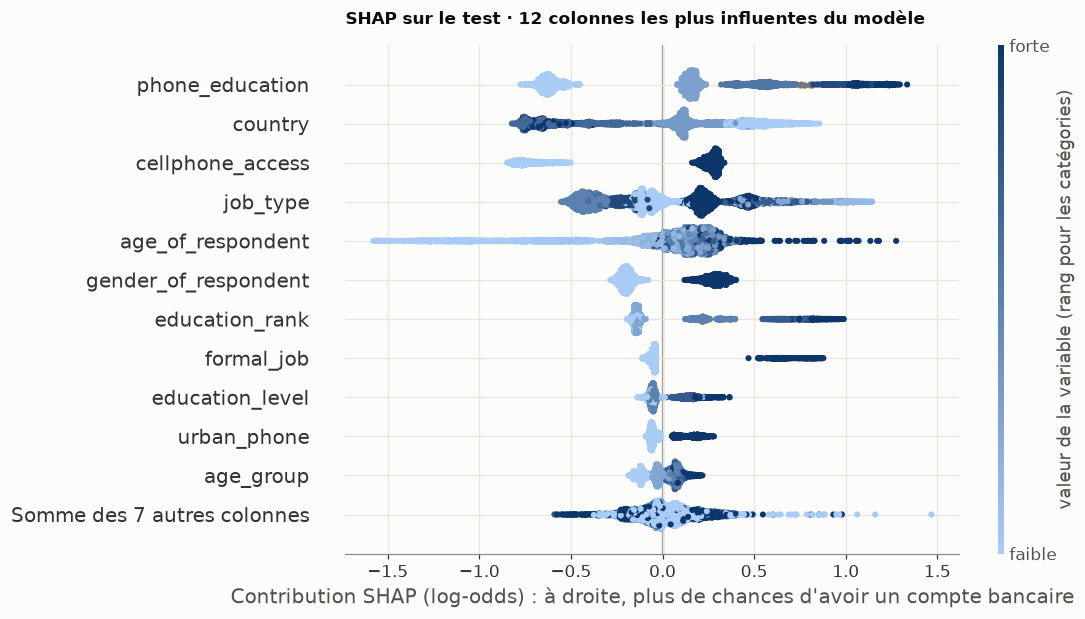

In [17]:
cmap = LinearSegmentedColormap.from_list("valeur", [viz.BLUES(0.25), viz.BLUES(1.0)])
X_codes = X_t.apply(lambda s: s.cat.codes if s.dtype == "category" else s)  # couleur : rang de la modalité
sv_plot = shap.Explanation(sv.values, sv.base_values, data=X_codes.to_numpy(), feature_names=list(X_t.columns))
shap.plots.beeswarm(sv_plot, max_display=12, color=cmap, show=False)
fig = plt.gcf()
fig.set_size_inches(9, 6)
ax = plt.gca()
ax.set_xlabel("Contribution SHAP (log-odds) : à droite, plus de chances d'avoir un compte bancaire")
ax.set_title("SHAP sur le test · 12 colonnes les plus influentes du modèle", loc="left", fontweight="bold")
ax.set_yticks(ax.get_yticks(), [t.get_text().replace("Sum of", "Somme des").replace("other features", "autres colonnes")
                                for t in ax.get_yticklabels()])
cbar = fig.axes[-1]
cbar.set_ylabel("valeur de la variable (rang pour les catégories)")
cbar.set_yticks(cbar.get_yticks(), ["faible", "forte"])
viz.save(fig, "11_shap_beeswarm")
plt.show()

Lecture : chaque point est une personne du test. Pour les variables numériques (âge, `education_rank`, `phone_education`), la couleur va du clair (valeur faible) au foncé (valeur forte) ; pour les catégories, elle n'indique que le rang alphabétique de la modalité. La colonne la plus influente, `phone_education`, est une **variable que nous avons construite** à l'étape 3 (téléphone × rang d'éducation) : le modèle s'en sert pour combiner les deux hypothèses H1 et H3.

### Q11.2 · Agréger par variable d'origine

Le guide évoque le one-hot, qui éclate une variable en une colonne par modalité. Avec les catégories natives, ce problème disparaît pour les catégories… mais nos **variables construites** éclatent encore certaines variables d'origine :

| Colonne du modèle | Variable(s) d'origine |
|---|---|
| `education_rank`, `education_unknown` | niveau d'éducation |
| `formal_job` | type d'emploi |
| `is_head` | lien avec le chef de ménage |
| `age_group` | âge |
| `lives_alone` | taille du ménage |
| `urban_phone` | milieu et téléphone (moitié chacun) |
| `phone_education` | téléphone et éducation (moitié chacun) |

Les valeurs SHAP sont **additives** : la contribution d'une variable d'origine est la **somme signée** des contributions de ses colonnes, personne par personne ; on prend ensuite la moyenne de la valeur absolue. (Additionner les valeurs absolues colonne par colonne surestimerait les variables dont les colonnes se compensent.) Les deux interactions sont partagées à parts égales entre leurs deux variables.

In [18]:
DERIVED = {
    "education_rank": {"education_level": 1.0}, "education_unknown": {"education_level": 1.0},
    "formal_job": {"job_type": 1.0}, "is_head": {"relationship_with_head": 1.0},
    "age_group": {"age_of_respondent": 1.0}, "lives_alone": {"household_size": 1.0},
    "urban_phone": {"location_type": 0.5, "cellphone_access": 0.5},
    "phone_education": {"cellphone_access": 0.5, "education_level": 0.5},
}
W = pd.DataFrame(0.0, index=X_t.columns, columns=RAW_COLS)  # colonne du modèle -> variable d'origine
for col in X_t.columns:
    for orig, w in DERIVED.get(col, {col: 1.0}).items():
        W.loc[col, orig] += w
shap_raw = pd.DataFrame(sv.values @ W.to_numpy(), columns=RAW_COLS, index=X_test.index)
assert np.allclose(shap_raw.sum(axis=1), sv.values.sum(axis=1))  # rien n'est perdu

shap_cols = pd.Series(np.abs(sv.values).mean(axis=0), index=X_t.columns).sort_values(ascending=False)
compare = pd.DataFrame({"SHAP agrégé (moyenne |somme|)": shap_raw.abs().mean(),
                        "permutation (baisse de PR-AUC)": perm["baisse de PR-AUC (moyenne)"]})
compare["rang SHAP"] = compare.iloc[:, 0].rank(ascending=False).astype(int)
compare["rang permutation"] = compare.iloc[:, 1].rank(ascending=False).astype(int)
display(shap_cols.round(3).to_frame("SHAP par colonne du modèle (moyenne |valeur|)"))
compare.sort_values("rang SHAP").round(4)

,SHAP par colonne du modèle (moyenne |valeur|)
phone_education,0.460
country,0.407
cellphone_access,0.389
job_type,0.296
age_of_respondent,0.258
gender_of_respondent,0.235
education_rank,0.213
formal_job,0.094
education_level,0.083
urban_phone,0.080


,SHAP agrégé (moyenne |somme|),permutation (baisse de PR-AUC),rang SHAP,rang permutation
cellphone_access,0.5749,0.0663,1,4
education_level,0.4473,0.2169,2,1
country,0.4069,0.0684,3,3
job_type,0.3501,0.1225,4,2
age_of_respondent,0.3194,0.0378,5,5
gender_of_respondent,0.2347,0.0093,6,7
location_type,0.0863,0.0211,7,6
relationship_with_head,0.0810,0.0046,8,8
household_size,0.0354,-0.0007,9,10
marital_status,0.0327,0.0023,10,9


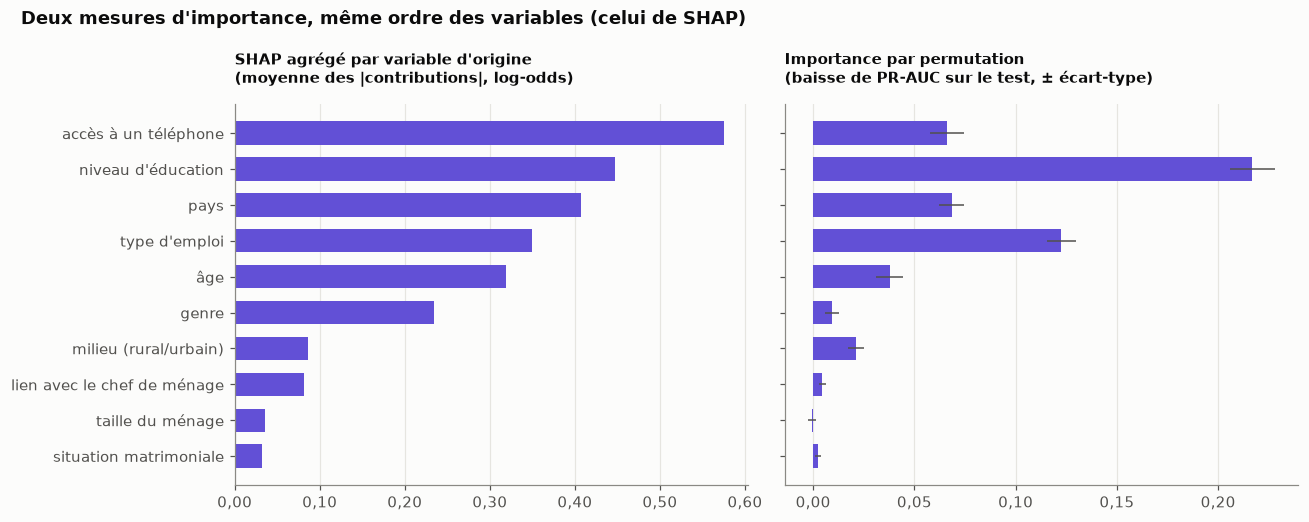

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
order = compare.sort_values("rang SHAP").index[::-1]
for ax, (col, title, fmt) in zip(axes, [
        ("SHAP agrégé (moyenne |somme|)", "SHAP agrégé par variable d'origine\n(moyenne des |contributions|, log-odds)", "{:.2f}"),
        ("permutation (baisse de PR-AUC)", "Importance par permutation\n(baisse de PR-AUC sur le test, ± écart-type)", "{:.2f}")]):
    vals = compare.loc[order, col]
    err = perm.loc[order, "écart-type"] if "permutation" in col else None
    ax.barh([LABELS[c] for c in order], vals, xerr=err, color=viz.COMPOSITION[1], height=0.65,
            error_kw={"ecolor": viz.INK_2, "elinewidth": 1})
    ax.set_title(title, fontsize=10)
    viz.fr_axis(ax, "x", fmt)
    ax.grid(axis="y", visible=False)
axes[1].set_yticklabels([])
fig.suptitle("Deux mesures d'importance, même ordre des variables (celui de SHAP)", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
viz.save(fig, "11_shap_contre_permutation")
plt.show()

**Réponse Q11.2.** Une fois agrégé, SHAP place en tête **téléphone, éducation, pays, type d'emploi et âge**, les mêmes cinq variables que la permutation, dans un ordre un peu différent. Les écarts s'expliquent par ce que mesure chaque méthode :

- **SHAP mesure de combien la prédiction bouge** (en log-odds), **la permutation ce que la PR-AUC perd**. Le téléphone déplace fortement la probabilité de presque tout le monde (1er en SHAP), mais une bonne partie de son information est aussi portée par l'éducation et le milieu : le mélanger seul coûte moins de PR-AUC (4e).
- **Le genre** illustre l'écart : 6e en SHAP (0,24 log-odds en moyenne), seulement 7e et minuscule en permutation (0,009). Il décale toutes les femmes vers le bas et tous les hommes vers le haut, mais ce décalage est en grande partie redondant avec ses proxys (lien avec le chef de ménage, situation matrimoniale, emploi) : quand on le mélange, le classement change peu.
- **Sans agrégation**, le classement par colonne trompe : `education_level` n'y est que 9e, parce que son effet est réparti entre `education_rank`, `phone_education` et la catégorie elle-même. Avec un one-hot, l'éclatement serait encore plus fort (une colonne par modalité).

Ce que les deux méthodes **ne disent pas** : ni l'une ni l'autre ne mesure un effet causal (Q11.5). Elles décrivent ce que **le modèle** utilise.

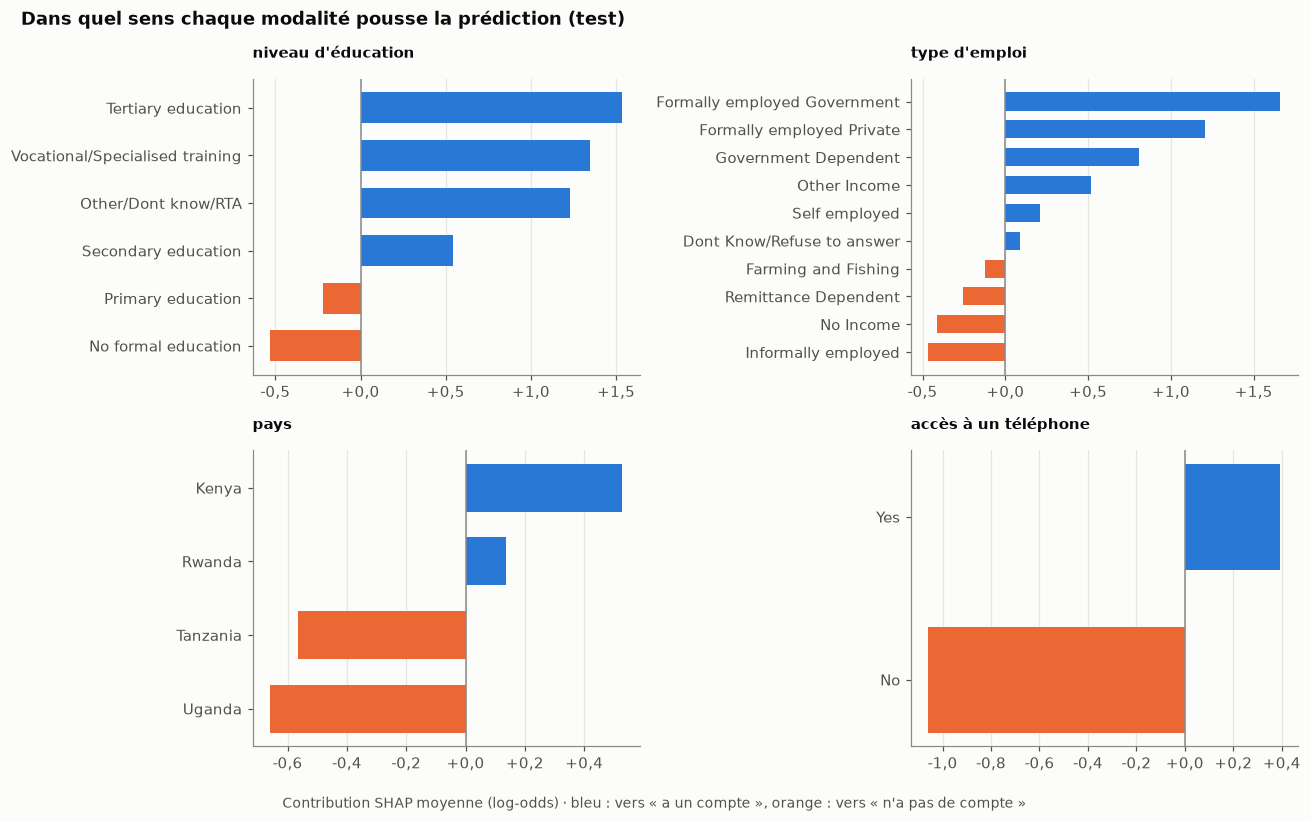

In [20]:
# Sens des effets : contribution SHAP moyenne de chaque modalité (variable d'origine)
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, var in zip(axes.flat, ["education_level", "job_type", "country", "cellphone_access"]):
    means = shap_raw[var].groupby(X_test[var]).mean().sort_values()
    colors = [viz.YES if v > 0 else viz.NO for v in means]
    ax.barh(means.index.astype(str), means, color=colors, height=0.65)
    ax.axvline(0, color=viz.INK_3, lw=1)
    ax.set_title(LABELS[var], fontsize=10)
    viz.fr_axis(ax, "x", "{:+.1f}")
    ax.grid(axis="y", visible=False)
fig.supxlabel("Contribution SHAP moyenne (log-odds) · bleu : vers « a un compte », orange : vers « n'a pas de compte »",
              fontsize=9, color=viz.INK_2)
fig.suptitle("Dans quel sens chaque modalité pousse la prédiction (test)", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
viz.save(fig, "11_shap_par_modalite")
plt.show()

### Q11.3 · Expliquer une prédiction

On choisit une personne du test par une règle fixée à l'avance : la première femme vivant en milieu rural, avec un téléphone, dont la probabilité est entre 0,15 et 0,30 (donc contactée) et qui a effectivement un compte. Pour qu'un agent de terrain puisse la lire, le graphique regroupe les contributions par **variable d'origine**.

In [21]:
mask = ((p_test > 0.15) & (p_test < 0.30) & (X_test["gender_of_respondent"] == "Female").to_numpy()
        & (X_test["location_type"] == "Rural").to_numpy() & (X_test["cellphone_access"] == "Yes").to_numpy()
        & (y_test == 1).to_numpy())
i = int(np.flatnonzero(mask)[0])
person = X_test.iloc[i]
contrib = shap_raw.iloc[i].sort_values(key=np.abs, ascending=False)
base = sv.base_values[i]
logit = base + contrib.sum()
print(f"Personne n° {X_test.index[i]} · probabilité {p_test[i]:.3f} (seuil {T_STAR:.3f}) · a un compte : {y_test.iloc[i]}")
display(person.to_frame("valeur"))
contrib.round(3).to_frame("contribution (log-odds)")

Personne n° 6835 · probabilité 0.183 (seuil 0.091) · a un compte : 1


,valeur
country,Rwanda
location_type,Rural
cellphone_access,Yes
gender_of_respondent,Female
relationship_with_head,Spouse
marital_status,Married/Living together
education_level,Secondary education
job_type,Remittance Dependent
household_size,3
age_of_respondent,26


,contribution (log-odds)
education_level,0.682
cellphone_access,0.506
job_type,-0.246
country,0.193
age_of_respondent,0.191
gender_of_respondent,-0.157
location_type,-0.068
relationship_with_head,-0.042
marital_status,0.033
household_size,0.011


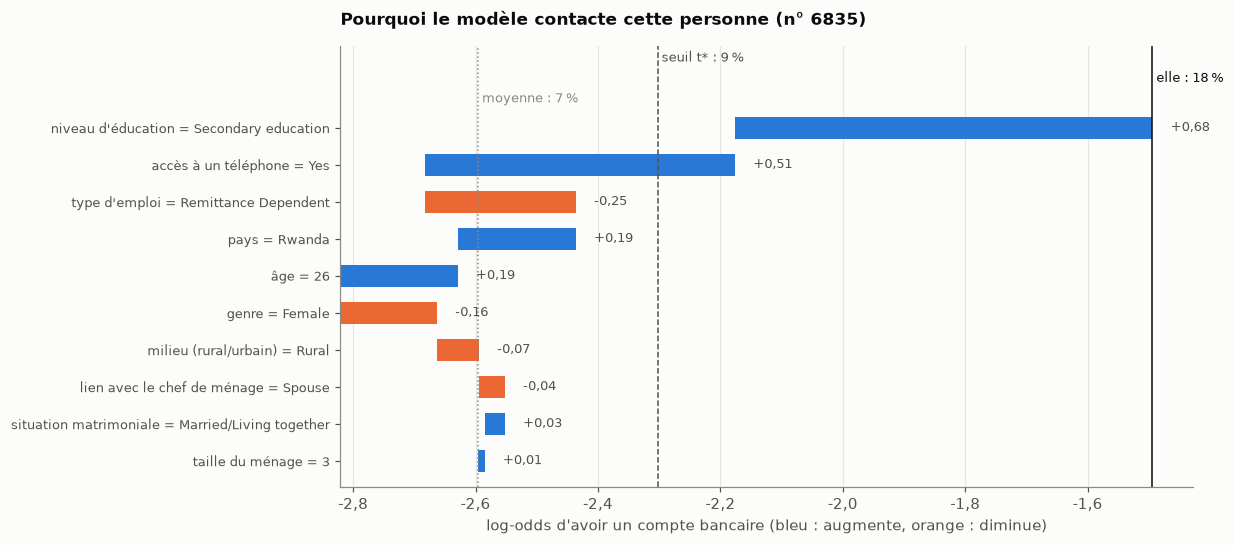

In [22]:
def proba(z):
    return 1 / (1 + np.exp(-z))

fig, ax = plt.subplots(figsize=(10, 5.2))
order = contrib.index[::-1]
start = base + contrib[contrib.index[::-1]].cumsum().shift(fill_value=0)  # cumul depuis la base
for k, var in enumerate(order):
    v = contrib[var]
    left = start[var] if v >= 0 else start[var] + v
    ax.barh(k, abs(v), left=left, color=viz.YES if v > 0 else viz.NO, height=0.6)
    ax.text(max(start[var], start[var] + v) + 0.03, k, viz.fr(f"{v:+.2f}"), va="center", fontsize=8.5, color=viz.INK_2)
ax.set_yticks(range(len(order)), [f"{LABELS[v]} = {person[v]}" for v in order], fontsize=8.5)
ax.axvline(base, color=viz.INK_3, ls=":", lw=1)
ax.axvline(logit, color=viz.INK, lw=1)
ax.axvline(np.log(T_STAR / (1 - T_STAR)), color=viz.INK_2, ls="--", lw=1)
ymax = len(order) - 0.4
ax.text(base, ymax, f" moyenne : {viz.fmt_pct(proba(base), 0)}", fontsize=8.5, color=viz.INK_3, va="bottom")
ax.text(logit, ymax + 0.55, f" elle : {viz.fmt_pct(proba(logit), 0)}", fontsize=8.5, va="bottom")
ax.text(np.log(T_STAR / (1 - T_STAR)), ymax + 1.1, f" seuil t* : {viz.fmt_pct(T_STAR, 0)}", fontsize=8.5,
        color=viz.INK_2, va="bottom")
ax.set_ylim(-0.7, len(order) + 1.2)
ax.set_xlabel("log-odds d'avoir un compte bancaire (bleu : augmente, orange : diminue)")
ax.set_title(f"Pourquoi le modèle contacte cette personne (n° {X_test.index[i]})", fontsize=11)
viz.fr_axis(ax, "x", "{:.1f}")
ax.grid(axis="y", visible=False)
viz.save(fig, "11_waterfall_une_personne")
plt.show()

**Réponse Q11.3.** Une jeune femme de 26 ans vivant à la campagne au Rwanda, qui a un téléphone et a fait des études secondaires : la personne « moyenne » a 7 chances sur 100 d'avoir un compte bancaire, elle environ 18.

> **Pour l'agent de terrain** : « Le téléphone et les études secondaires de cette personne sont les deux raisons principales pour lesquelles elle a plus de chances que la moyenne d'avoir un compte ; vivre de l'argent envoyé par la famille et le fait d'être une femme les font un peu baisser. Au total, environ 18 chances sur 100, au-dessus du seuil de 9 sur 100 : on la contacte. »

Le modèle avait raison : elle a un compte. On remarque que **le genre fait baisser sa probabilité** : c'est l'objet de Q11.4.

### Q11.4 · Le genre

**Le genre contribue-t-il ?** Oui : contribution SHAP moyenne de 0,24 log-odds (6e variable), négative pour les femmes, positive pour les hommes.

In [23]:
print(shap_raw["gender_of_respondent"].groupby(X_test["gender_of_respondent"]).mean().round(3).to_string())

def by_gender(y, p, g, threshold=T_STAR):
    rows = {}
    for gender in ["Female", "Male"]:
        m = np.asarray(g) == gender
        yy, contact = np.asarray(y)[m], np.asarray(p)[m] >= threshold
        rows[gender] = {"personnes": int(m.sum()), "part qui a un compte": yy.mean(),
                        "probabilité moyenne prédite": np.asarray(p)[m].mean(), "part contactée": contact.mean(),
                        "recall": (contact & (yy == 1)).sum() / yy.sum(),
                        "précision": (contact & (yy == 1)).sum() / contact.sum()}
    return pd.DataFrame(rows).T

g_test = X_test["gender_of_respondent"].to_numpy()
test_gender = by_gender(y_test, p_test, g_test)
display(test_gender.round(3))

# Écart de recall hommes − femmes sur le test : intervalle bootstrap
rng = np.random.default_rng(RS)
yv = y_test.to_numpy()
gaps = []
for _ in range(1000):
    idx = rng.integers(0, len(yv), len(yv))
    t = by_gender(yv[idx], p_test[idx], g_test[idx])
    gaps.append(t.loc["Male", "recall"] - t.loc["Female", "recall"])
gap = test_gender.loc["Male", "recall"] - test_gender.loc["Female", "recall"]
print(f"Écart de recall hommes − femmes sur le test : {gap:.3f}, IC 95 % [{np.percentile(gaps, 2.5):.3f} ; "
      f"{np.percentile(gaps, 97.5):.3f}]")

gender_of_respondent
Female   -0.199
Male      0.286


,personnes,part qui a un compte,probabilité moyenne prédite,part contactée,recall,précision
Female,2792.0,0.109,0.109,0.298,0.826,0.302
Male,1913.0,0.187,0.196,0.556,0.919,0.309


Écart de recall hommes − femmes sur le test : 0.093, IC 95 % [0.049 ; 0.140]


**Avec ou sans le genre ?** Comme prévu en Q1.6, on entraîne la même procédure **sans** la variable (colonne remplacée par une valeur constante) et on compare **par validation croisée sur le train**, pas sur le test : c'est une décision, elle ne doit pas être prise sur le test (Q10.3).

In [24]:
X_train_ng = X_train.assign(gender_of_respondent="masqué")
row_ng, res_ng = evaluate_cv(models.make_final(), X_train_ng, y_train, name="sans le genre")
display(format_summary(pd.DataFrame([cv_row, row_ng]), metrics=["pr_auc", "brier", "cost_t", "recall_t"]))
for metric in ["pr_auc", "cost_t"]:
    d = paired_difference(cv_res, res_ng, metric)
    print(f"{metric:<7} sans − avec : {d['différence moyenne B − A']:+.4f} (erreur-type {d['erreur-type des différences']:.4f}, "
          f"plis où « sans » a le plus grand score : {d['plis où B > A']}/5)")

p_oof_with = cross_val_predict(models.make_final(), X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
p_oof_without = cross_val_predict(models.make_final(), X_train_ng, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
g_train = X_train["gender_of_respondent"].to_numpy()
audit = pd.concat({"avec le genre": by_gender(y_train, p_oof_with, g_train),
                   "sans le genre": by_gender(y_train, p_oof_without, g_train)})
audit.round(3)

,pr_auc,brier,cost_t,recall_t,temps (s)
LightGBM réglé,0.581 ± 0.024,0.085 ± 0.003,0.244 ± 0.012,0.852 ± 0.020,0.61
sans le genre,0.578 ± 0.024,0.085 ± 0.003,0.242 ± 0.015,0.853 ± 0.021,0.62


pr_auc  sans − avec : -0.0039 (erreur-type 0.0020, plis où « sans » a le plus grand score : 1/5)
cost_t  sans − avec : -0.0020 (erreur-type 0.0026, plis où « sans » a le plus grand score : 2/5)


personnes  part qui a un compte  \
avec le genre Female    11085.0                 0.106   
              Male       7734.0                 0.190   
sans le genre Female    11085.0                 0.106   
              Male       7734.0                 0.190   

                      probabilité moyenne prédite  part contactée  recall  \
avec le genre Female                        0.107           0.294   0.781   
              Male                          0.190           0.550   0.909   
sans le genre Female                        0.116           0.328   0.815   
              Male                          0.177           0.495   0.884   

                      précision  
avec le genre Female      0.282  
              Male        0.315  
sans le genre Female      0.264  
              Male        0.340

In [25]:
# Les proxys : peut-on deviner le genre à partir des autres variables ?
from sklearn.metrics import roc_auc_score
is_female = (X_train["gender_of_respondent"] == "Female").astype(int)
p_female = cross_val_predict(models.make_final(), X_train_ng, is_female, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
print(f"ROC-AUC pour deviner le genre sans la colonne genre : {roc_auc_score(is_female, p_female):.3f}")
pd.crosstab(X_train["relationship_with_head"], X_train["gender_of_respondent"], normalize="index").round(3)

ROC-AUC pour deviner le genre sans la colonne genre : 0.910


gender_of_respondent,Female,Male
relationship_with_head,,
Child,0.522,0.478
Head of Household,0.404,0.596
Other non-relatives,0.584,0.416
Other relative,0.543,0.457
Parent,0.559,0.441
Spouse,0.985,0.015


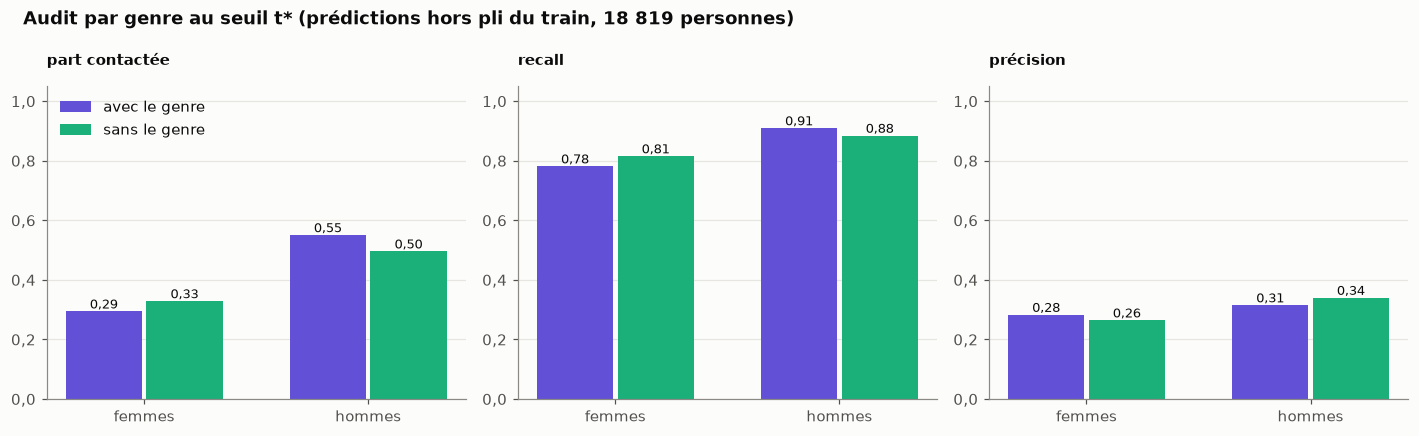

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
versions = {"avec le genre": viz.COMPOSITION[1], "sans le genre": viz.COMPOSITION[0]}
for ax, metric in zip(axes, ["part contactée", "recall", "précision"]):
    x = np.arange(2)
    for k, (version, color) in enumerate(versions.items()):
        vals = audit.loc[version].loc[["Female", "Male"], metric]
        bars = ax.bar(x + (k - 0.5) * 0.36, vals, width=0.34, color=color, label=version)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.01, viz.fr(f"{v:.2f}"), ha="center", fontsize=8.5)
    ax.set_xticks(x, ["femmes", "hommes"])
    ax.set_ylim(0, 1.05)
    ax.set_title(metric, fontsize=10)
    viz.fr_axis(ax, "y", "{:.1f}")
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper left")
fig.suptitle("Audit par genre au seuil t* (prédictions hors pli du train, 18 819 personnes)", x=0.02, ha="left",
             fontweight="bold")
fig.tight_layout()
viz.save(fig, "11_audit_genre")
plt.show()

**Réponse Q11.4.**

- **Oui, le genre contribue** : il fait baisser la probabilité de chaque femme (SHAP moyen environ −0,2 log-odds) et monter celle de chaque homme (environ +0,3).
- **Écart de recall** au seuil $t^*$ : sur le test, le modèle retrouve **83 % des femmes** qui ont un compte contre **92 % des hommes** (écart de 9 points, IC 95 % bootstrap [5 ; 14] : l'écart est réel) ; hors pli sur le train, 78 % contre 91 %. Une femme qui a un compte a donc plus de deux fois plus de risques d'être oubliée qu'un homme (22 % contre 9 % hors pli).
- **Sans la variable** (validation croisée, même procédure) : PR-AUC 0,578 contre 0,581, une petite perte régulière (−0,004, 4 plis sur 5, deux erreurs-types appariées) mais six fois plus petite que l'écart-type entre plis ; coût par personne **inchangé** (0,242 contre 0,244, dans le bruit) ; et l'écart de recall est **divisé par deux** (82 % des femmes contre 88 % des hommes).
- **L'écart ne disparaît pas** : sans la colonne, les autres variables devinent encore le genre avec une ROC-AUC de 0,91. *Spouse* est une femme dans 99 % des cas (et, en Tanzanie, 1 799 lignes cumulent *Spouse* et *Single/Never Married*, une incohérence relevée en Q2.6) ; la situation matrimoniale et l'emploi portent aussi le genre. Une partie de l'écart vient enfin de la réalité : 10,6 % des femmes ont un compte contre 19,0 % des hommes.

**Retour sur Q1.6. Pour KaziPay, on ne garderait pas cette variable** : elle n'apporte très peu en performance (et rien en coût), elle aggrave l'écart de traitement et elle entretiendrait la boucle que le projet veut casser (moins de femmes contactées, donc moins de femmes équipées). **Ce qu'on changerait** :

1. entraîner le modèle de ciblage **sans le genre** (coût équivalent, écart de recall divisé par deux) ;
2. **garder le genre dans les données pour l'audit** : suivre le recall et la part contactée par genre à chaque nouvelle version, avec un écart maximal fixé à l'avance ;
3. surveiller les **proxys** (*Spouse*, situation matrimoniale) et vérifier la qualité des données tanzaniennes ;
4. pour réduire encore l'écart, agir sur la **campagne** plutôt que sur le modèle (canaux qui touchent les femmes, partenaires locaux). Des seuils différents par genre égaliseraient le recall, mais réintroduiraient le genre dans la décision : c'est un choix juridique et éthique, pas technique.

Pour la **banque centrale**, qui estime des totaux sans décider pour une personne, garder le genre pose moins de problème.

> **Cohérence avec Q10.3** : le modèle sans le genre est une recommandation, évaluée par validation croisée uniquement. Les chiffres du test (étape 10) restent ceux du modèle évalué ; si l'on déploie la version sans le genre, il faut la mesurer sur de nouvelles données, ou documenter une seconde consultation du test.

### Q11.5 · « Donner un téléphone fait ouvrir un compte » ?

Part des personnes qui ont un compte bancaire, selon le téléphone et le niveau d'éducation (train) :

In [27]:
tab = pd.crosstab(X_train["education_level"], X_train["cellphone_access"], values=y_train, aggfunc="mean")
tab["effectif sans téléphone"] = pd.crosstab(X_train["education_level"], X_train["cellphone_access"])["No"]
tab.round(3)

cellphone_access,No,Yes,effectif sans téléphone
education_level,,,
No formal education,0.019,0.055,1595
Other/Dont know/RTA,0.000,0.533,6
Primary education,0.011,0.113,2687
Secondary education,0.031,0.267,484
Tertiary education,0.061,0.539,66
Vocational/Specialised training,0.118,0.589,17


**Réponse Q11.5. Non, on ne peut pas le conclure.** Le modèle, SHAP et la permutation mesurent une **association** : parmi des personnes semblables par ailleurs dans les données, celles qui ont un téléphone ont plus souvent un compte. Ils ne disent pas ce qui se passerait si l'on **donnait** un téléphone à quelqu'un :

- **Facteurs de confusion** : le revenu, l'emploi formel, l'éducation et la vie en ville font à la fois acheter un téléphone et ouvrir un compte. Le tableau montre que l'écart persiste à niveau d'éducation égal, mais d'autres causes communes non mesurées (revenu, distance à une agence) restent possibles ; le jeu ne contient pas le revenu.
- **Causalité inverse** : avoir un compte (salaire versé à la banque, application bancaire) peut pousser à avoir un téléphone.
- **SHAP explique le modèle, pas le monde** : une contribution SHAP dit comment la **prédiction** change avec la variable, toutes choses du modèle égales ; ce n'est pas l'effet d'une intervention.

Pour mesurer un effet causal, il faudrait une **expérience** (distribuer des téléphones au hasard à un groupe et comparer à un groupe témoin), ou une expérience naturelle crédible. Pour KaziPay, ce n'est pas un problème : le modèle sert à **prédire** qui contacter, pas à décider d'une politique ; l'association suffit pour cibler.

> **Q2.6, rappel** : `job_type` n'a pas le même codage selon les pays (par exemple, pas de *Farming and Fishing* en Tanzanie et en Ouganda) ; son importance mêle donc l'effet de l'emploi et celui du pays, et ne doit pas être lue comme un effet de l'emploi seul.

### Synthèse de l'étape 11

- **Ce que le modèle utilise** : éducation, type d'emploi, pays, téléphone et âge, dans cet ordre par permutation ; téléphone, éducation, pays, emploi et âge par SHAP agrégé. Les trois hypothèses de Q2.7 sont confirmées.
- **Agréger** les colonnes par variable d'origine est indispensable, même sans one-hot, à cause des variables construites.
- **Genre** : il contribue et creuse l'écart de recall (78 % des femmes retrouvées contre 91 % des hommes, hors pli). Sans lui, même coût et écart divisé par deux : on recommande de l'**exclure du ciblage** et de le **garder pour l'audit**.
- **Corrélation n'est pas causalité** : le modèle prédit, il ne dit pas quoi changer dans le monde.

**Étape 12** : publier le projet (README final, limites, reproduction).